# HW1：奇異值分解（SVD）與彩色影像壓縮

課程講師：施因澤 教授｜羅志緯（5115050039）

**目標**
1. 以程式驗證 $\|A-A_k\|_2=\sigma_{k+1}$，其中 $A_k=\sum_{i=1}^{k}\sigma_i u_i v_i^T$，$0<k<p$。
2. 以壓縮比（Compression Ratio, CR）與峰值訊噪比（Peak Signal-to-Noise Ratio, PSNR）決定最佳的 $k$。

**評估指標**：均方誤差（Mean Squared Error, MSE）與 PSNR 定義為

$$
\text{MSE}=\frac{1}{mn}\|A-A_k\|_F^2,\qquad
\text{PSNR}=10\log_{10}\!\left(\frac{255^2}{\text{MSE}}\right)=20\log_{10}\!\left(\frac{255}{\sqrt{\text{MSE}}}\right)
$$

奇異值依慣例排序為 $\sigma_1\ge\sigma_2\ge\cdots\ge\sigma_p\ge 0$。

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

IMG_PATH = 'DSCF3773.jpg'
FIG_DIR = Path('figures'); FIG_DIR.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 200, 'savefig.bbox': 'tight'})
pd.set_option('display.float_format', lambda x: f'{x:.6g}')

## 1. 讀入影像

彩色影像是 $m\times n\times 3$ 的 Tensor。題目的定理是針對**單一矩陣**，因此本作業採用兩種方式把彩色影像變成矩陣：

- **方法一（分層法）**：R、G、B 三個 channel 各自是 $m\times n$ 矩陣，分別做 SVD，取相同的 $k$ 後疊回。
- **方法二（並排法）**：把三個 channel 並排成 $X=[R\mid G\mid B]\in\mathbb{R}^{m\times 3n}$，只做一次 SVD，三個 channel 共用左奇異向量 $U$。

影像以 `float64` 讀入，避免 `uint8` 相減時溢位（例如 `np.uint8(3) - np.uint8(5)` 會得到 254）。

影像大小 m x n x 3 = 1000 x 1000 x 3
p = min(m, n) = 1000，k 的範圍為 1 ~ 999


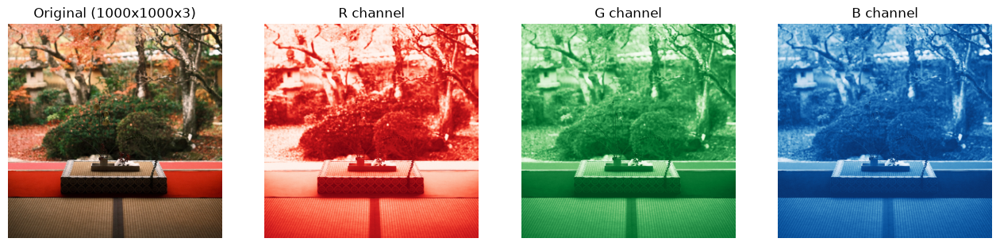

In [2]:
img = Image.open(IMG_PATH).convert('RGB')
A_rgb = np.asarray(img, dtype=np.float64)   # 用 float64，避免 uint8 相減時溢位
m, n, _ = A_rgb.shape
p = min(m, n)
R, G, B = (A_rgb[:, :, c] for c in range(3))
channels = {'R': R, 'G': G, 'B': B}
print(f'影像大小 m x n x 3 = {m} x {n} x 3')
print(f'p = min(m, n) = {p}，k 的範圍為 1 ~ {p-1}')

fig, ax = plt.subplots(1, 4, figsize=(16, 4.3))
ax[0].imshow(img); ax[0].set_title(f'Original ({m}x{n}x3)')
for a, (c, M), cmap in zip(ax[1:], channels.items(), ['Reds_r', 'Greens_r', 'Blues_r']):
    a.imshow(M, cmap=cmap, vmin=0, vmax=255); a.set_title(f'{c} channel')
for a in ax: a.axis('off')
fig.savefig(FIG_DIR / '01_original_channels.png'); plt.show()

## 2. SVD 分解

`np.linalg.svd(..., full_matrices=False)` 回傳 thin SVD：$U\in\mathbb{R}^{m\times p}$、$s\in\mathbb{R}^{p}$、$V^T\in\mathbb{R}^{p\times n}$。
由於 $A_k$ 只用到前 $k$ 個奇異向量，這和題目的完整 SVD 得到的 $A_k$ 完全相同。

In [3]:
svd_ch = {c: np.linalg.svd(M, full_matrices=False) for c, M in channels.items()}
X = np.hstack([R, G, B])                      # 方法二：m x 3n
svd_X = np.linalg.svd(X, full_matrices=False)

for c in 'RGB':
    U, s, Vt = svd_ch[c]
    print(f'{c}: U {U.shape}, s {s.shape}, Vt {Vt.shape}, sigma_1 = {s[0]:.1f}, sigma_p = {s[-1]:.4f}')
U, s, Vt = svd_X
print(f'[R|G|B]: U {U.shape}, s {s.shape}, Vt {Vt.shape}, sigma_1 = {s[0]:.1f}, sigma_p = {s[-1]:.4f}')
print('奇異值是否遞減排序:', all(np.all(np.diff(svd_ch[c][1]) <= 0) for c in 'RGB') and np.all(np.diff(svd_X[1]) <= 0))

R: U (1000, 1000), s (1000,), Vt (1000, 1000), sigma_1 = 131849.1, sigma_p = 0.1691
G: U (1000, 1000), s (1000,), Vt (1000, 1000), sigma_1 = 97277.8, sigma_p = 0.0898
B: U (1000, 1000), s (1000,), Vt (1000, 1000), sigma_1 = 71159.4, sigma_p = 0.0140
[R|G|B]: U (1000, 1000), s (1000,), Vt (1000, 3000), sigma_1 = 177518.2, sigma_p = 28.6673
奇異值是否遞減排序: True


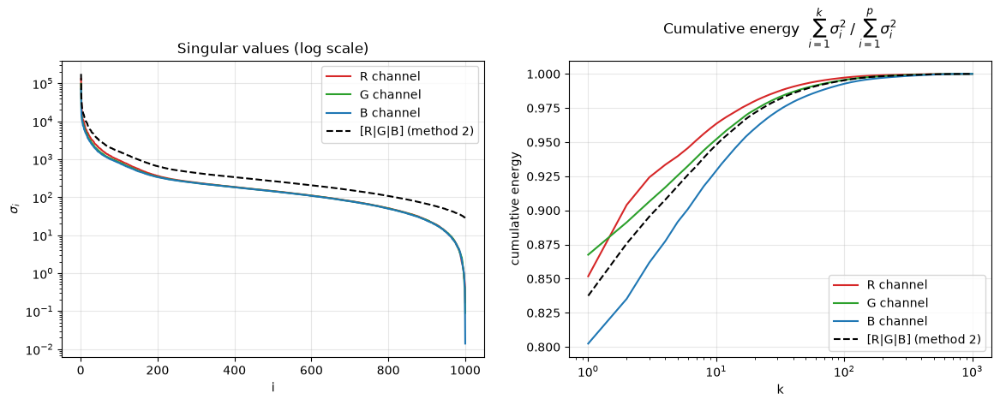

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
idx = np.arange(1, p + 1)
for c, col in zip('RGB', ['tab:red', 'tab:green', 'tab:blue']):
    s = svd_ch[c][1]
    ax[0].semilogy(idx, s, color=col, label=f'{c} channel')
    ax[1].plot(idx, np.cumsum(s**2) / np.sum(s**2), color=col, label=f'{c} channel')
s = svd_X[1]
ax[0].semilogy(idx, s, 'k--', label='[R|G|B] (method 2)')
ax[1].plot(idx, np.cumsum(s**2) / np.sum(s**2), 'k--', label='[R|G|B] (method 2)')
ax[0].set(title='Singular values (log scale)', xlabel='i', ylabel=r'$\sigma_i$')
ax[1].set(xlabel='k', ylabel='cumulative energy', xscale='log')
ax[1].set_title(r'Cumulative energy  $\sum_{i=1}^{k}\sigma_i^2 \; / \; \sum_{i=1}^{p}\sigma_i^2$', pad=22)
for a in ax: a.grid(alpha=.3); a.legend()
fig.savefig(FIG_DIR / '02_singular_values.png'); plt.show()

**SVD 把影像拆成一層一層相加**：$A=\sum_i \sigma_i u_i v_i^T$。每一層 $u_i v_i^T$ 都是「行向量 × 列向量」形成的格子圖案，$\sigma_i$ 是這一層的權重。上排是 R channel 的單一層（紅正藍負），下排是前 $k$ 層相加的結果 $A_k$。

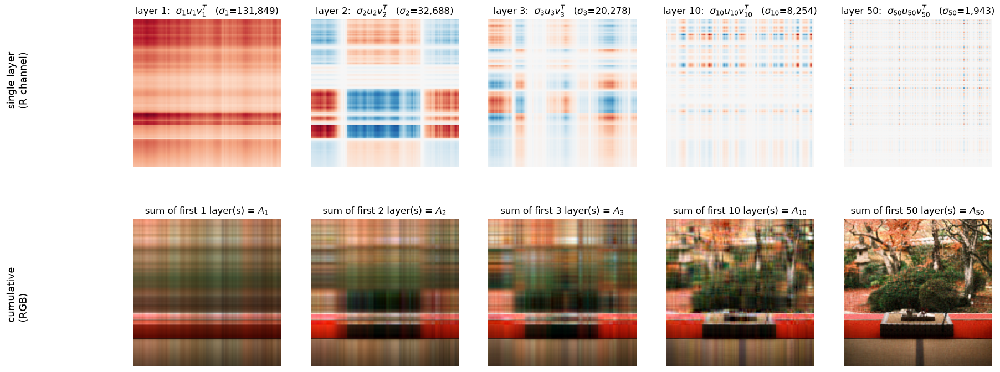

In [5]:
K_LAYER = [1, 2, 3, 10, 50]
fig, ax = plt.subplots(2, 5, figsize=(20, 8.6))
U, s, Vt = svd_ch['R']
for j, k in enumerate(K_LAYER):
    L = s[k-1] * np.outer(U[:, k-1], Vt[k-1])
    v = np.abs(L).max()
    ax[0, j].imshow(L, cmap='RdBu_r', vmin=-v, vmax=v)
    ax[0, j].set_title(rf'layer {k}:  $\sigma_{{{k}}} u_{{{k}}} v_{{{k}}}^T$   ($\sigma_{{{k}}}$={s[k-1]:,.0f})', fontsize=12)
    Ak = np.dstack([(svd_ch[c][0][:, :k] * svd_ch[c][1][:k]) @ svd_ch[c][2][:k] for c in 'RGB'])
    ax[1, j].imshow(np.clip(np.rint(Ak), 0, 255).astype(np.uint8))
    ax[1, j].set_title(rf'sum of first {k} layer(s) = $A_{{{k}}}$', fontsize=12)
for a in ax.flat: a.axis('off')
fig.text(0.01, 0.73, 'single layer\n(R channel)', fontsize=13, rotation=90, va='center')
fig.text(0.01, 0.28, 'cumulative\n(RGB)', fontsize=13, rotation=90, va='center')
fig.savefig(FIG_DIR / '08_rank1_layers.png'); plt.show()

## 3. 工具函式

重點：**計算誤差、範數、MSE 時一律用 float 的 $A_k$**；只有在「顯示或存成圖檔」時才裁切到 $[0,255]$ 並四捨五入成 `uint8`。

In [6]:
def rank_k(U, s, Vt, k):
    # A_k = sum_{i=1}^{k} sigma_i u_i v_i^T（保持 float，不裁切、不取整）
    return (U[:, :k] * s[:k]) @ Vt[:k, :]

def to_uint8(M):
    # 只在顯示 / 存檔時使用
    return np.clip(np.rint(M), 0, 255).astype(np.uint8)

def reconstruct_rgb(k, method):
    if method == 1:
        return np.dstack([rank_k(*svd_ch[c], k) for c in 'RGB'])
    return np.dstack(np.hsplit(rank_k(*svd_X, k), 3))

def cr_method1(k):   # 每個 channel 存 k 個 u (m)、k 個 v (n)、k 個 sigma；三個 channel 分子分母同乘 3
    return m * n / ((m + n + 1) * k)

def cr_method2(k):   # 共用 U：存 k 個 u (m)、k 個 v (3n)、k 個 sigma
    return 3 * m * n / ((m + 3 * n + 1) * k)

def mse(A, Ak):
    return np.mean((A - Ak) ** 2)          # = ||A - A_k||_F^2 / (像素值個數)

def psnr(A, Ak, peak=255.0):
    return 10 * np.log10(peak ** 2 / mse(A, Ak))

## 4. 驗證 $\|A-A_k\|_2=\sigma_{k+1}$

對 R、G、B 三個矩陣（方法一）以及並排矩陣 $[R\mid G\mid B]$（方法二）分別驗證。
注意 Python 索引從 0 開始，所以 $\sigma_{k+1}$ 是 `s[k]`。

同時順便驗證 Frobenius 範數的對應結果 $\|A-A_k\|_F^2=\sum_{i=k+1}^{p}\sigma_i^2$，後面計算 MSE 會用到。

In [7]:
K_TEST = [1, 5, 10, 20, 50, 100, 200, 300, 500, 700, 900, p - 1]
targets = [(c, svd_ch[c], channels[c]) for c in 'RGB'] + [('[R|G|B]', svd_X, X)]

rows = []
for name, (U, s, Vt), M in targets:
    for k in K_TEST:
        E = M - rank_k(U, s, Vt, k)           # 誤差矩陣 A - A_k（和右式的 s 分開計算）
        two = np.linalg.norm(E, 2)            # 2-norm = 最大奇異值
        sig = s[k]                            # sigma_{k+1}
        fro2 = np.linalg.norm(E, 'fro') ** 2
        rows.append({'matrix': name, 'k': k, '||A-A_k||_2': two, 'sigma_{k+1}': sig,
                     'abs diff': abs(two - sig), 'rel diff': abs(two - sig) / sig,
                     'Frobenius rel diff': abs(fro2 - np.sum(s[k:] ** 2)) / fro2})
ver = pd.DataFrame(rows)
ver.to_csv(FIG_DIR / 'verification_2norm.csv', index=False)
ver[ver.matrix == 'R'].drop(columns='matrix').reset_index(drop=True)

,k,||A-A_k||_2,sigma_{k+1},abs diff,rel diff,Frobenius rel diff
0,1,32688.4,32688.4,2.54659e-11,7.79048e-16,9.45249e-16
1,5,11032.1,11032.1,0,0,5.81333e-16
2,10,7387.8,7387.8,2.72848e-12,3.69323e-16,3.19717e-16
3,20,4381.51,4381.51,4.54747e-12,1.03788e-15,8.8159e-16
4,50,1907.99,1907.99,6.82121e-13,3.57507e-16,0
5,100,933.342,933.342,0,0,6.65967e-16
6,200,363.286,363.286,3.97904e-13,1.09529e-15,0
7,300,242.369,242.369,0,0,7.13131e-16
8,500,145.41,145.41,3.97904e-13,2.73642e-15,1.47001e-16
9,700,79.8066,79.8066,9.9476e-14,1.24646e-15,3.84125e-16


In [8]:
ver[ver.matrix == '[R|G|B]'].drop(columns='matrix').reset_index(drop=True)

,k,||A-A_k||_2,sigma_{k+1},abs diff,rel diff,Frobenius rel diff
0,1,37981.3,37981.3,0,0,0
1,5,17584.1,17584.1,7.27596e-12,4.13781e-16,3.0828e-16
2,10,12063.4,12063.4,1.81899e-12,1.50785e-16,1.09585e-15
3,20,6883.37,6883.37,9.09495e-12,1.32129e-15,2.22165e-16
4,50,3057.85,3057.85,5.91172e-12,1.93329e-15,7.16892e-16
5,100,1582.98,1582.98,2.72848e-12,1.72364e-15,3.38543e-16
6,200,652.641,652.641,5.68434e-13,8.70975e-16,0
7,300,438.291,438.291,3.41061e-13,7.78161e-16,1.46979e-15
8,500,265.986,265.986,3.41061e-13,1.28225e-15,4.79757e-16
9,700,154.428,154.428,5.96856e-13,3.86494e-15,5.0874e-16


In [9]:
summary = ver.groupby('matrix', sort=False)[['abs diff', 'rel diff', 'Frobenius rel diff']].max()
summary.columns = ['max abs diff', 'max rel diff', 'max Frobenius rel diff']
summary

,max abs diff,max rel diff,max Frobenius rel diff
matrix,,,
R,2.54659e-11,2.1559e-12,4.31275e-12
G,2.18279e-11,2.40564e-12,4.81175e-12
B,1.27329e-11,6.94829e-12,1.38956e-11
[R|G|B],9.09495e-12,3.86494e-15,3.73509e-15


所有矩陣、所有 $k$ 的相對誤差都只有約 $10^{-16}\sim10^{-11}$，只是浮點數的捨入誤差，所以 $\|A-A_k\|_2=\sigma_{k+1}$ 成立。

**常見錯誤示範**：如果拿「裁切、取整後的 `uint8` 影像」來算，或直接用 `uint8` 相減，等式就不會成立：

In [10]:
k = 50
U, s, Vt = svd_ch['R']
Rk = rank_k(U, s, Vt, k)
correct = np.linalg.norm(R - Rk, 2)
rounded = np.linalg.norm(R - to_uint8(Rk), 2)                                   # 用顯示用的影像計算
overflow = np.linalg.norm((R.astype(np.uint8) - to_uint8(Rk)).astype(float), 2)  # uint8 直接相減
print(f'sigma_{k+1}                      = {s[k]:.6f}')
print(f'float A_k（正確）               = {correct:.6f}')
print(f'裁切取整後的 A_k                 = {rounded:.6f}')
print(f'uint8 直接相減（溢位）           = {overflow:.6f}')

sigma_51                      = 1907.993167
float A_k（正確）               = 1907.993167
裁切取整後的 A_k                 = 1889.116469
uint8 直接相減（溢位）           = 120147.664434


## 5. 不同 $k$ 的重建結果（方法一與方法二）

同一個 $k$ 下兩種方法並列。注意相同 $k$ 時兩者的 CR 不同（方法一每層存 6003 個數值、方法二 4001 個），公平比較請見第 8 節的相同 CR 比較。

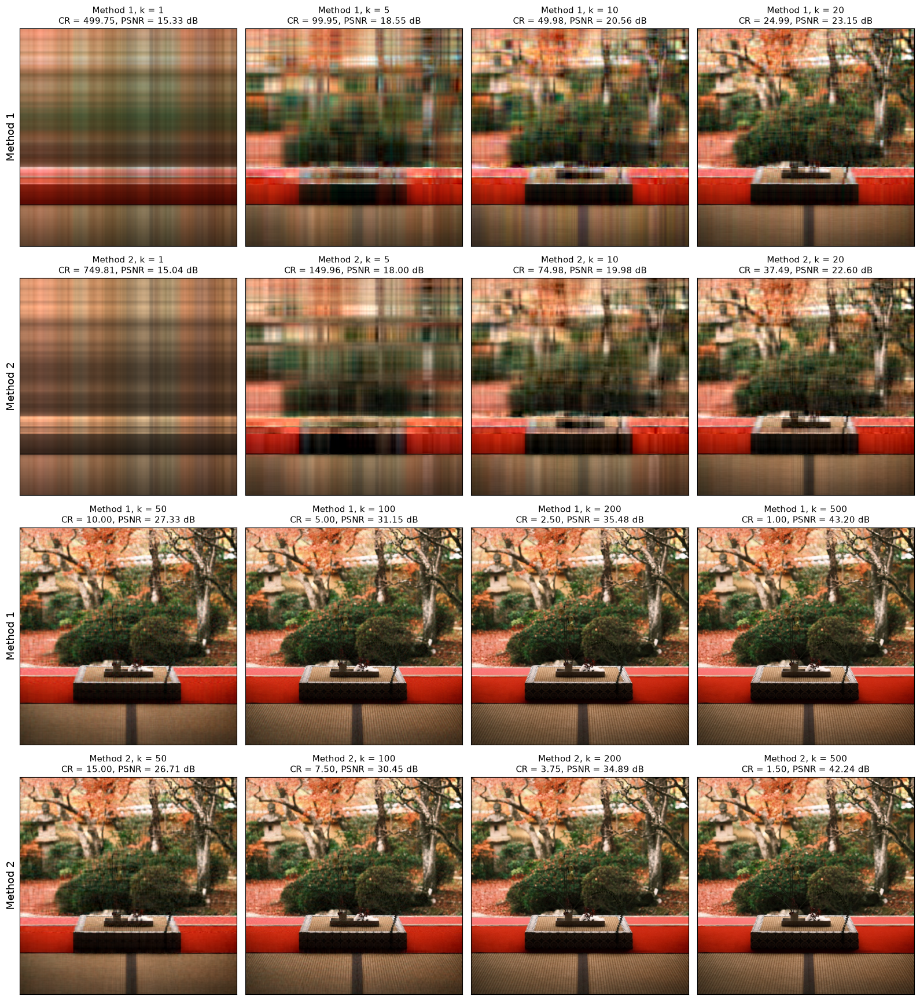

In [11]:
K_SHOW = [1, 5, 10, 20, 50, 100, 200, 500]
fig, axes = plt.subplots(4, 4, figsize=(16, 17.5))
for j, k in enumerate(K_SHOW):
    blk, col = divmod(j, 4)
    for r, method in enumerate([1, 2]):
        Ak = reconstruct_rgb(k, method)
        cr = cr_method1(k) if method == 1 else cr_method2(k)
        a = axes[2 * blk + r, col]
        a.imshow(to_uint8(Ak)); a.set_xticks([]); a.set_yticks([])
        a.set_title(f'Method {method}, k = {k}\nCR = {cr:.2f}, PSNR = {psnr(A_rgb, Ak):.2f} dB', fontsize=11)
for r in range(4):
    axes[r, 0].set_ylabel(f'Method {1 + r % 2}', fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / '03_reconstructions.png'); plt.show()

## 6. 所有 $k$ 的 CR 與 PSNR

$$
\text{CR}_{\text{方法一}}=\frac{mn}{(m+n+1)k},\qquad
\text{CR}_{\text{方法二}}=\frac{3mn}{(m+3n+1)k}
$$

彩色影像的 MSE 取全部 $3mn$ 個像素值的平均。利用第 4 節驗證過的 $\|A-A_k\|_F^2=\sum_{i>k}\sigma_i^2$，可以不必重建影像就算出每個 $k$ 的 MSE：

$$
\text{MSE}_{\text{方法一}}=\frac{1}{3mn}\sum_{c\in\{R,G,B\}}\sum_{i>k}\sigma_{c,i}^2,\qquad
\text{MSE}_{\text{方法二}}=\frac{1}{3mn}\sum_{i>k}\sigma_{X,i}^2
$$

In [12]:
ks = np.arange(1, p)                  # 0 < k < p
N = 3 * m * n

def tail_energy(s, ks):               # sum_{i>k} sigma_i^2
    e = np.cumsum((s ** 2)[::-1])[::-1]  # 從後往前累加：e[j] = s[j]^2 + ... + s[p-1]^2
    return e[ks]                         # 0-based，所以 e[k] 正好是 sigma_{k+1}^2 + ... + sigma_p^2

sse1 = sum(tail_energy(svd_ch[c][1], ks) for c in 'RGB')
sse2 = tail_energy(svd_X[1], ks)
df = pd.DataFrame({'k': ks,
                   'CR_m1': cr_method1(ks), 'MSE_m1': sse1 / N, 'PSNR_m1': 10 * np.log10(255 ** 2 / (sse1 / N)),
                   'CR_m2': cr_method2(ks), 'MSE_m2': sse2 / N, 'PSNR_m2': 10 * np.log10(255 ** 2 / (sse2 / N))})
df.to_csv(FIG_DIR / 'metrics_all_k.csv', index=False)

k_even1 = m * n / (m + n + 1)
k_even2 = 3 * m * n / (m + 3 * n + 1)
print(f'CR = 1 的 break-even point：方法一 k = {k_even1:.1f}，方法二 k = {k_even2:.1f}')
print(f'因此有壓縮效果（CR > 1）的範圍：方法一 k <= {int(np.ceil(k_even1)) - 1}，方法二 k <= {int(np.ceil(k_even2)) - 1}')

CR = 1 的 break-even point：方法一 k = 499.8，方法二 k = 749.8
因此有壓縮效果（CR > 1）的範圍：方法一 k <= 499，方法二 k <= 749


**交叉檢查**：用公式算的 PSNR 和實際重建影像算的 PSNR 應該一致。最後一欄是存成 `uint8` 圖檔後的 PSNR（多了取整誤差，k 很大時會略低）。

In [13]:
chk = []
for k in [1, 10, 50, 100, 300, 500]:
    Ak = reconstruct_rgb(k, 1)
    chk.append({'k': k, 'PSNR (formula)': df.PSNR_m1[k - 1], 'PSNR (float A_k)': psnr(A_rgb, Ak),
                'PSNR (uint8 image)': psnr(A_rgb, to_uint8(Ak).astype(float))})
pd.DataFrame(chk)

,k,PSNR (formula),PSNR (float A_k),PSNR (uint8 image)
0,1,15.3291,15.3291,15.3298
1,10,20.559,20.559,20.5741
2,50,27.3343,27.3343,27.3506
3,100,31.1522,31.1522,31.1629
4,300,38.0277,38.0277,38.0008
5,500,43.2042,43.2042,43.1043


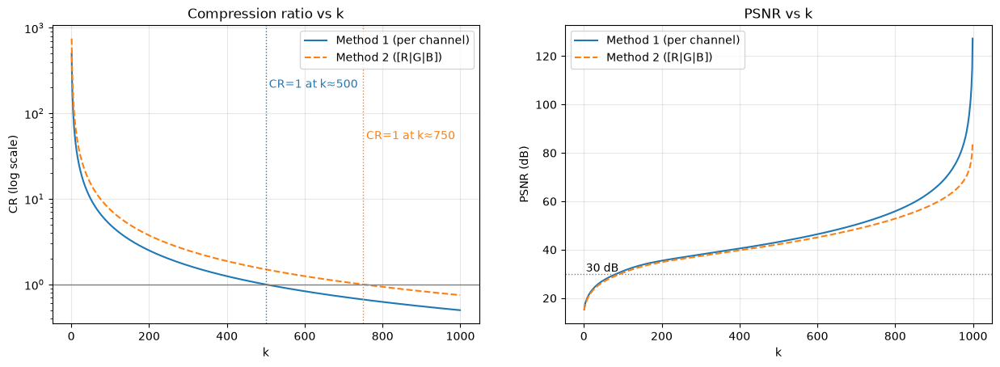

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
ax[0].semilogy(df.k, df.CR_m1, label='Method 1 (per channel)')
ax[0].semilogy(df.k, df.CR_m2, '--', label='Method 2 ([R|G|B])')
ax[0].axhline(1, color='gray', lw=1)
ax[0].axvline(k_even1, color='tab:blue', ls=':', lw=1); ax[0].axvline(k_even2, color='tab:orange', ls=':', lw=1)
ax[0].text(k_even1, 200, f' CR=1 at k≈{k_even1:.0f}', color='tab:blue')
ax[0].text(k_even2, 50, f' CR=1 at k≈{k_even2:.0f}', color='tab:orange')
ax[0].set(title='Compression ratio vs k', xlabel='k', ylabel='CR (log scale)')
ax[1].plot(df.k, df.PSNR_m1, label='Method 1 (per channel)')
ax[1].plot(df.k, df.PSNR_m2, '--', label='Method 2 ([R|G|B])')
ax[1].axhline(30, color='gray', ls=':', lw=1); ax[1].text(5, 31, '30 dB')
ax[1].set(title='PSNR vs k', xlabel='k', ylabel='PSNR (dB)')
for a in ax: a.grid(alpha=.3); a.legend()
fig.savefig(FIG_DIR / '04_cr_psnr_vs_k.png'); plt.show()

### 各矩陣的維度

thin SVD 下，$U\in\mathbb{R}^{m\times p}$、$V^T\in\mathbb{R}^{p\times n}$；截斷到 $k$ 後需儲存 $U_k$（$m\times k$）、$\Sigma_k$ 的 $k$ 個對角元素、$V_k^T$（$k\times n$）。

In [15]:
dims = pd.DataFrame({
    'Method 1 (each of R, G, B)': [f'{m} x {n}  (x3)', f'{m} x {p}', f'{p}', f'{p} x {n}', f'{m} x k', 'k x k (store k)', f'k x {n}',
                                   f'3 x ({m}+{n}+1)k = {3*(m+n+1)}k', f'{3*m*n:,}', f'{k_even1:.1f}'],
    'Method 2 ([R|G|B])':         [f'{m} x {3*n}', f'{m} x {p}', f'{p}', f'{p} x {3*n}', f'{m} x k', 'k x k (store k)', f'k x {3*n}',
                                   f'({m}+{3*n}+1)k = {m+3*n+1}k', f'{3*m*n:,}', f'{k_even2:.1f}'],
}, index=['matrix A', 'U (thin SVD)', 'number of sigma', 'V^T (thin SVD)', 'U_k', 'Sigma_k', 'V_k^T',
          'stored values', 'original values (3mn)', 'break-even k (CR = 1)'])
dims

,"Method 1 (each of R, G, B)",Method 2 ([R|G|B])
matrix A,1000 x 1000 (x3),1000 x 3000
U (thin SVD),1000 x 1000,1000 x 1000
number of sigma,1000,1000
V^T (thin SVD),1000 x 1000,1000 x 3000
U_k,1000 x k,1000 x k
Sigma_k,k x k (store k),k x k (store k)
V_k^T,k x 1000,k x 3000
stored values,3 x (1000+1000+1)k = 6003k,(1000+3000+1)k = 4001k
original values (3mn),"3,000,000","3,000,000"
break-even k (CR = 1),499.8,749.8


### 各 $k$ 值的完整結果

節省空間比例 $=(1-1/\text{CR})\times100\%$，CR $<1$ 時為負值，代表壓縮後反而比原圖大。

In [16]:
K_TABLE1 = [1, 5, 10, 20, 30, 50, 80, 83, 100, 116, 150, 200, 300, 500, 700, 900, p - 1]   # 含 k*=83 與 knee k=116
K_TABLE2 = [1, 5, 10, 20, 30, 50, 80, 94, 100, 150, 200, 300, 500, 700, 900, p - 1]        # 含方法二 k*=94

def full_table(method, ks):
    rows = []
    for k in ks:
        r = df.iloc[k - 1]
        if method == 1:
            stored, cr, e, ps, vt = 3 * (m + n + 1) * k, r.CR_m1, r.MSE_m1, r.PSNR_m1, f'{k} x {n}'
        else:
            stored, cr, e, ps, vt = (m + 3 * n + 1) * k, r.CR_m2, r.MSE_m2, r.PSNR_m2, f'{k} x {3 * n}'
        rows.append({'k': k, 'U_k': f'{m} x {k}', 'Sigma_k': f'{k} x {k}', 'V_k^T': vt,
                     'stored values': stored, 'CR': cr, 'space saved (%)': (1 - 1 / cr) * 100,
                     'MSE': e, 'PSNR (dB)': ps})
    return pd.DataFrame(rows)

full_table(1, K_TABLE1)

,k,U_k,Sigma_k,V_k^T,stored values,CR,space saved (%),MSE,PSNR (dB)
0,1,1000 x 1,1 x 1,1 x 1000,6003,499.75,99.7999,1906.23,15.3291
1,5,1000 x 5,5 x 5,5 x 1000,30015,99.95,98.9995,908.848,18.5459
2,10,1000 x 10,10 x 10,10 x 1000,60030,49.975,97.999,571.712,20.559
3,20,1000 x 20,20 x 20,20 x 1000,120060,24.9875,95.998,314.875,23.1494
4,30,1000 x 30,30 x 30,30 x 1000,180090,16.6583,93.997,210.065,24.9073
5,50,1000 x 50,50 x 50,50 x 1000,300150,9.995,89.995,120.13,27.3343
6,80,1000 x 80,80 x 80,80 x 1000,480240,6.24688,83.992,68.1179,29.7982
7,83,1000 x 83,83 x 83,83 x 1000,498249,6.02109,83.3917,64.886,30.0093
8,100,1000 x 100,100 x 100,100 x 1000,600300,4.9975,79.99,49.872,31.1522
9,116,1000 x 116,116 x 116,116 x 1000,696348,4.30819,76.7884,39.9572,32.1149


In [17]:
full_table(2, K_TABLE2)

,k,U_k,Sigma_k,V_k^T,stored values,CR,space saved (%),MSE,PSNR (dB)
0,1,1000 x 1,1 x 1,1 x 3000,4001,749.813,99.8666,2038.93,15.0368
1,5,1000 x 5,5 x 5,5 x 3000,20005,149.963,99.3332,1031.18,17.9975
2,10,1000 x 10,10 x 10,10 x 3000,40010,74.9813,98.6663,652.695,19.9837
3,20,1000 x 20,20 x 20,20 x 3000,80020,37.4906,97.3327,357.72,22.5954
4,30,1000 x 30,30 x 30,30 x 3000,120030,24.9938,95.999,241.037,24.31
5,50,1000 x 50,50 x 50,50 x 3000,200050,14.9963,93.3317,138.572,26.7141
6,80,1000 x 80,80 x 80,80 x 3000,320080,9.37266,89.3307,79.4002,29.1326
7,94,1000 x 94,94 x 94,94 x 3000,376094,7.97673,87.4635,64.068,30.0644
8,100,1000 x 100,100 x 100,100 x 3000,400100,7.49813,86.6633,58.6875,30.4454
9,150,1000 x 150,150 x 150,150 x 3000,600150,4.99875,79.995,31.8127,33.1048


## 7. 決定最佳 $k$

CR 隨 $k$ 遞減、PSNR 隨 $k$ 遞增，兩者互相拉扯，所以要先定一個選擇標準。本作業採用：

> **在 PSNR $\ge 30$ dB 的條件下，使 CR 最大**（也就是取滿足條件的最小 $k$），並要求 CR $>1$。

30 dB 是 8-bit 影像有損壓縮常用的「可接受品質」下限（一般有損壓縮的 PSNR 約落在 30～50 dB）。
因為門檻怎麼選有一點主觀，下面也列出不同門檻的結果，並用曲線的 knee point 再確認一次。

In [18]:
PSNR_TARGET = 30.0

def best_k(psnr_col, cr_col, target):
    ok = (df[psnr_col] >= target) & (df[cr_col] > 1)
    return int(df.k[ok].iloc[0]) if ok.any() else None   # k 由小到大，第一個符合的 k 就是 CR 最大的

k_star = best_k('PSNR_m1', 'CR_m1', PSNR_TARGET)
k_star2 = best_k('PSNR_m2', 'CR_m2', PSNR_TARGET)
print(f'方法一：k* = {k_star}，CR = {cr_method1(k_star):.3f}，PSNR = {df.PSNR_m1[k_star - 1]:.2f} dB')
print(f'方法二：k* = {k_star2}，CR = {cr_method2(k_star2):.3f}，PSNR = {df.PSNR_m2[k_star2 - 1]:.2f} dB')

sens = []
for T in [25, 30, 35, 40]:
    k1, k2 = best_k('PSNR_m1', 'CR_m1', T), best_k('PSNR_m2', 'CR_m2', T)
    sens.append({'PSNR target (dB)': T, 'k (m1)': k1, 'CR (m1)': cr_method1(k1),
                 'k (m2)': k2, 'CR (m2)': cr_method2(k2)})
pd.DataFrame(sens)

方法一：k* = 83，CR = 6.021，PSNR = 30.01 dB
方法二：k* = 94，CR = 7.977，PSNR = 30.06 dB


,PSNR target (dB),k (m1),CR (m1),k (m2),CR (m2)
0,25,31,16.121,35,21.4232
1,30,83,6.02109,94,7.97673
2,35,185,2.70135,204,3.67555
3,40,381,1.31168,411,1.82436


**用 knee point 再確認一次**：在 CR $>1$ 的範圍內，把 $k$ 與 PSNR 都縮放到 $[0,1]$，取離「兩端點連線」最遠的點，也就是 PSNR 開始明顯變緩的位置。

In [19]:
def knee_k(psnr_col, cr_col):
    d = df[df[cr_col] > 1]                                  # 只看有壓縮效果的範圍
    x = (d.k - d.k.min()) / (d.k.max() - d.k.min())
    y = (d[psnr_col] - d[psnr_col].min()) / (d[psnr_col].max() - d[psnr_col].min())
    # 縮放後兩端點是 (0,0) 與 (1,1)，離兩點連線最遠的點就是 y - x 最大的點
    return int(d.k.iloc[np.argmax((y - x).values)])

k_knee = knee_k('PSNR_m1', 'CR_m1')
print(f'方法一 knee point：k = {k_knee}，CR = {cr_method1(k_knee):.3f}，PSNR = {df.PSNR_m1[k_knee - 1]:.2f} dB')

方法一 knee point：k = 116，CR = 4.308，PSNR = 32.11 dB


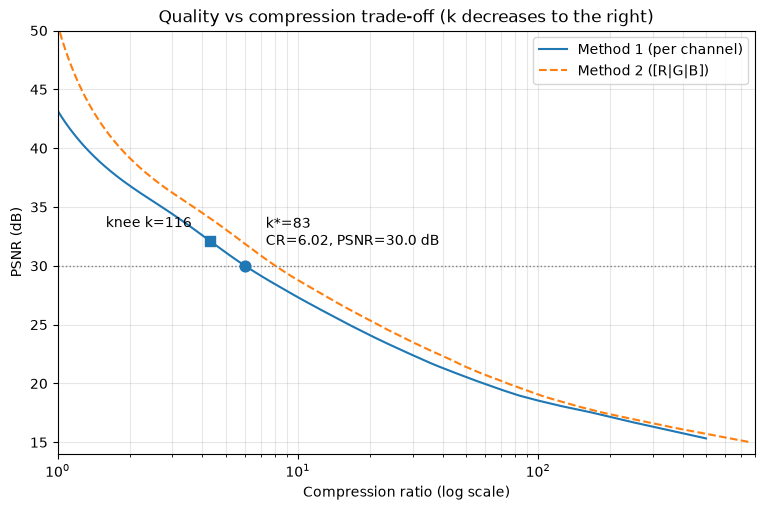

In [20]:
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(df.CR_m1, df.PSNR_m1, label='Method 1 (per channel)')
ax.plot(df.CR_m2, df.PSNR_m2, '--', label='Method 2 ([R|G|B])')
ax.scatter(cr_method1(k_star), df.PSNR_m1[k_star - 1], color='tab:blue', zorder=5, s=60)
ax.annotate(f'k*={k_star}\nCR={cr_method1(k_star):.2f}, PSNR={df.PSNR_m1[k_star - 1]:.1f} dB',
            (cr_method1(k_star), df.PSNR_m1[k_star - 1]), xytext=(15, 15), textcoords='offset points')
ax.scatter(cr_method1(k_knee), df.PSNR_m1[k_knee - 1], color='tab:blue', marker='s', zorder=5, s=50)
ax.annotate(f'knee k={k_knee}', (cr_method1(k_knee), df.PSNR_m1[k_knee - 1]), xytext=(-75, 10), textcoords='offset points')
ax.axhline(PSNR_TARGET, color='gray', ls=':', lw=1)
ax.set(xscale='log', xlim=(1, 800), ylim=(14, 50), xlabel='Compression ratio (log scale)', ylabel='PSNR (dB)',
       title='Quality vs compression trade-off (k decreases to the right)')
ax.grid(alpha=.3, which='both'); ax.legend()
fig.savefig(FIG_DIR / '05_psnr_vs_cr.png'); plt.show()

### 視覺檢查

PSNR 是整張圖的平均指標，所以也放大局部（花藝與榻榻米紋理）目視比較，並畫出誤差圖 $|A-A_k|$（三個 channel 平均）。

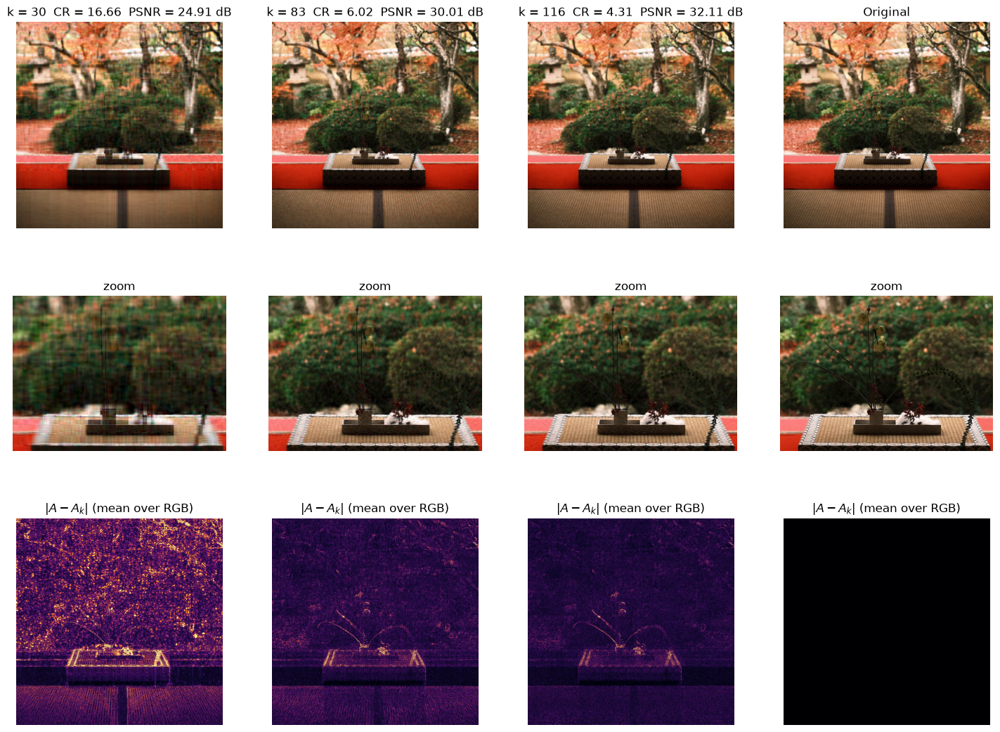

In [21]:
K_CMP = [30, k_star, k_knee]
crop = (slice(330, 730), slice(200, 750))          # 花藝與坐墊區域
fig, axes = plt.subplots(3, len(K_CMP) + 1, figsize=(18, 13))
for j, k in enumerate(K_CMP + [None]):
    Ak = A_rgb if k is None else reconstruct_rgb(k, 1)
    title = 'Original' if k is None else f'k = {k}  CR = {cr_method1(k):.2f}  PSNR = {psnr(A_rgb, Ak):.2f} dB'
    axes[0, j].imshow(to_uint8(Ak)); axes[0, j].set_title(title)
    axes[1, j].imshow(to_uint8(Ak)[crop]); axes[1, j].set_title('zoom')
    axes[2, j].imshow(np.abs(A_rgb - Ak).mean(axis=2), cmap='inferno', vmin=0, vmax=40)
    axes[2, j].set_title(r'$|A - A_k|$ (mean over RGB)')
for a in axes.flat: a.axis('off')
fig.savefig(FIG_DIR / '06_visual_comparison.png'); plt.show()

## 8. 兩種彩色方法的比較

在**相同 CR** 下比較 PSNR（以內插取值）：

In [22]:
cmp = []
for cr in [2, 4, 6, 10, 20, 50]:
    # CR 隨 k 遞減，但 np.interp 需要遞增的 x，所以把順序反過來
    p1 = np.interp(cr, df.CR_m1[::-1], df.PSNR_m1[::-1])
    p2 = np.interp(cr, df.CR_m2[::-1], df.PSNR_m2[::-1])
    cmp.append({'CR': cr, 'k (m1)': m * n / ((m + n + 1) * cr), 'PSNR m1 (dB)': p1,
                'k (m2)': 3 * m * n / ((m + 3 * n + 1) * cr), 'PSNR m2 (dB)': p2, 'gain (dB)': p2 - p1})
pd.DataFrame(cmp)

,CR,k (m1),PSNR m1 (dB),k (m2),PSNR m2 (dB),gain (dB)
0,2,249.875,36.7986,374.906,39.1454,2.34676
1,4,124.938,32.5993,187.453,34.5032,1.90393
2,6,83.2917,30.0299,124.969,31.896,1.8661
3,10,49.975,27.3318,74.9813,28.78,1.44824
4,20,24.9875,24.0939,37.4906,25.3539,1.25997
5,50,9.995,20.5575,14.9963,21.4153,0.857849


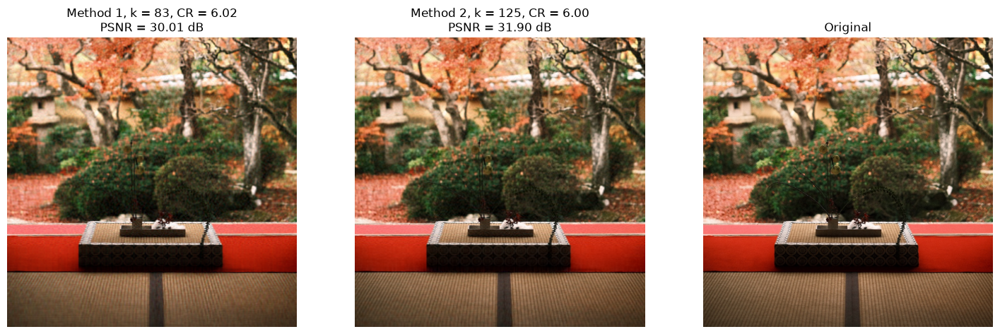

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
k2_same_cr = int(round(3 * m * n / ((m + 3 * n + 1) * cr_method1(k_star))))   # 方法二中與方法一 k* 的 CR 相同的 k
for a, (Ak, t) in zip(axes, [(reconstruct_rgb(k_star, 1), f'Method 1, k = {k_star}, CR = {cr_method1(k_star):.2f}'),
                             (reconstruct_rgb(k2_same_cr, 2), f'Method 2, k = {k2_same_cr}, CR = {cr_method2(k2_same_cr):.2f}'),
                             (A_rgb, 'Original')]):
    a.imshow(to_uint8(Ak)); a.axis('off')
    a.set_title(t if Ak is A_rgb else f'{t}\nPSNR = {psnr(A_rgb, Ak):.2f} dB')
fig.savefig(FIG_DIR / '07_method_comparison.png'); plt.show()

### 為什麼方法二比較好？

方法二比較好，是因為三個通道很像：如果 R、G、B 的主要結構一樣，三組 $U_k$ 就會幾乎相同，方法一等於重複存了三次。
下面用兩個指標來檢查：像素值的相關係數，以及兩組 $U_k$ 的重疊程度
$\|U_k^{(a)T}U_k^{(b)}\|_F^2/k$（1 表示完全一樣，0 表示方向完全不同）。

In [24]:
corr = np.corrcoef(np.vstack([R.ravel(), G.ravel(), B.ravel()]))   # R、G、B 像素的 3x3 相關係數矩陣
U_ch = {c: svd_ch[c][0] for c in 'RGB'}

def overlap(Ua, Ub, k):   # 1 表示兩組 U_k 張成的空間完全一樣；隨機方向約為 k/m
    return np.linalg.norm(Ua[:, :k].T @ Ub[:, :k], 'fro') ** 2 / k

rows = []
for a, b in [('R', 'G'), ('R', 'B'), ('G', 'B')]:
    rows.append({'pair': f'{a}-{b}', 'pixel correlation': corr['RGB'.index(a), 'RGB'.index(b)],
                 f'overlap k={k_star2}': overlap(U_ch[a], U_ch[b], k_star2)})
ov = pd.DataFrame(rows)
ov.to_csv(FIG_DIR / 'channel_overlap.csv', index=False)
print(f'random subspaces would give about k/m = {k_star2 / m:.3f}')
ov

random subspaces would give about k/m = 0.094


,pair,pixel correlation,overlap k=94
0,R-G,0.82092,0.855199
1,R-B,0.788919,0.822491
2,G-B,0.970733,0.93517


## 9. 結論

**1. 定理驗證**：對 R、G、B 三個 $1000\times1000$ 矩陣與並排矩陣 $[R\mid G\mid B]$（$1000\times3000$），在 $k=1$ 到 $999$ 的 12 個取值下，$\|A-A_k\|_2$ 與 $\sigma_{k+1}$ 的相對差距最大約 $10^{-11}$，屬於浮點數誤差，證實 $\|A-A_k\|_2=\sigma_{k+1}$；Frobenius 範數的 $\|A-A_k\|_F^2=\sum_{i>k}\sigma_i^2$ 也同樣成立。計算時必須用 float 的 $A_k$，若用裁切取整後的影像或 `uint8` 直接相減，等式就不會成立。

**2. CR 的有效範圍**：方法一在 $k\approx500$、方法二在 $k\approx750$ 時 CR $=1$，超過這個 $k$ 時 SVD 需要儲存的資料反而比原圖多，沒有壓縮意義。

**3. 最佳 $k$**：以「PSNR $\ge30$ dB 下使 CR 最大」為標準，方法一的最佳值為 **$k^*=83$**，CR $=6.02$、PSNR $=30.01$ dB，也就是只用約 $1/6$ 的資料量就保留了可接受的畫質。目視上庭園、紅色緣側、坐墊花紋與花藝都清楚可辨，只有最細的枝條略為模糊。knee point 分析得到 $k=116$（CR $=4.31$、PSNR $=32.11$ dB），$k^*$ 落在 knee point 之前，代表再減少 $k$ 會讓畫質快速下降；若想要更保守的畫質，$k=116$ 是合理的替代選擇。不同門檻的結果見第 7 節的表格。

**4. 兩種彩色方法：方法二較好**。在相同 CR 下，方法二（三個 channel 共用 $U$）的 PSNR 在 CR $>1$ 的範圍內都比方法一高，CR 在 2 到 50 之間高約 0.9～2.3 dB；以 30 dB 為門檻時，方法二只需 $k=94$ 即可達到 CR $=7.98$（方法一為 6.02），相同畫質下多壓縮約 32%。原因是三個 channel 高度相關（G、B 相關係數 0.97），各自的 $U_k$ 重疊約 82%～94%，方法一等於重複存了很相似的 $U_k$。方法一的唯一優勢是各通道可以分別選擇不同的 $k$。

**限制**：CR 公式假設每個儲存的數值與一個像素的成本相同，但實際上 $U$、$V$、$\sigma$ 是浮點數（4 或 8 bytes），而像素只佔 1 byte，因此實際檔案的壓縮比會比公式值低。